# 01 - Explore CICIDS2017
Run `python -m ingest.load_cicids` first. This notebook checks that the cleaned data is sane and answers the questions that shape the project: what attacks exist, when they happen, and how much of the data is repeated.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INTERIM = ROOT / "data" / "interim"
files = sorted(INTERIM.glob("*.parquet"))
print(len(files), "parquet files found")

8 parquet files found


## 1. What the cleaning removed
Put these numbers in your write-up. They show you cleaned the data before measuring anything.

In [2]:
rep = pd.read_csv(INTERIM / "_cleaning_report.csv")
rep["pct_dropped"] = ((rep.rows_raw - rep.rows_clean) / rep.rows_raw * 100).round(1)
rep[["file", "rows_raw", "dropped_inf_nan", "dropped_duplicates", "rows_clean", "pct_dropped", "attack_rows"]]

,file,rows_raw,dropped_inf_nan,dropped_duplicates,rows_clean,pct_dropped,attack_rows
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,34,2,225709,0.0,128025
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,371,1,286095,0.1,158804
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,122,2,190909,0.1,1956
3,Monday-WorkingHours.pcap_ISCX.csv,529918,437,31,529450,0.1,0
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,207,142,288253,0.1,36
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,458968,135,1,170230,62.9,2180
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,264,4,445641,0.1,13832
7,Wednesday-workingHours.pcap_ISCX.csv,692703,1297,16,691390,0.2,251722


## 2. Load a light copy (only the columns we need here)

In [3]:
cols = ["timestamp", "label", "is_attack", "day", "source_file"]
df = pd.concat([pd.read_parquet(f, columns=cols) for f in files], ignore_index=True)
df["label"] = df["label"].astype("category")
print(f"{len(df):,} flows, {df.memory_usage(deep=True).sum()/1e6:.0f} MB in RAM")

2,827,677 flows, 211 MB in RAM


## 3. Class balance
BENIGN dominates, and some attacks are tiny classes. This is why accuracy is a misleading metric and the project reports precision, recall and F1 per class.

,flows,pct
label,,
BENIGN,2271122,80.318
DoS Hulk,230123,8.138
PortScan,158804,5.616
DDoS,128025,4.528
DoS GoldenEye,10293,0.364
FTP-Patator,7935,0.281
SSH-Patator,5897,0.209
DoS slowloris,5796,0.205
DoS Slowhttptest,5499,0.194


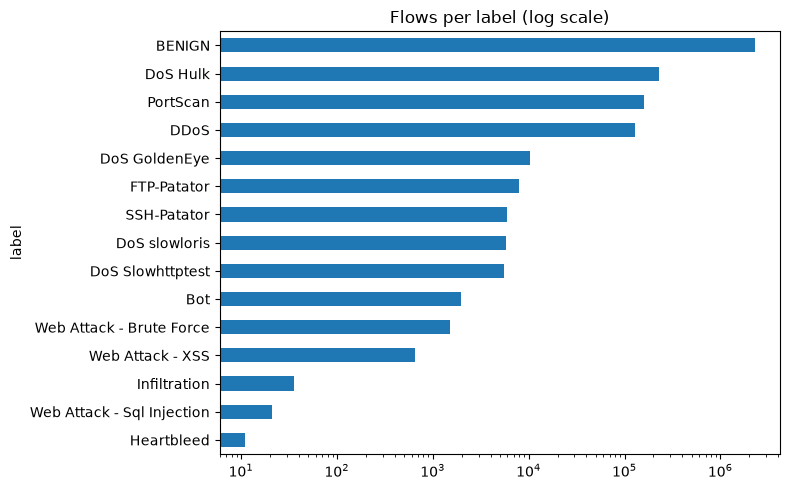

In [4]:
counts = df["label"].value_counts()
display(counts.to_frame("flows").assign(pct=(counts / counts.sum() * 100).round(3)))
counts.sort_values().plot.barh(logx=True, figsize=(8, 5), title="Flows per label (log scale)")
plt.tight_layout(); plt.show()

## 4. Timestamp sanity check
CICIDS2017 timestamps have no AM/PM and `clean.py` fixes them with a heuristic. Each file should span roughly 08:00 to 17:00.

In [5]:
df.groupby("source_file")["timestamp"].agg(["min", "max"])

,min,max
source_file,,
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,2017-07-07 15:30:00,2017-07-07 17:02:00
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,2017-07-07 13:00:00,2017-07-07 15:29:00
Friday-WorkingHours-Morning.pcap_ISCX.csv,2017-07-07 08:59:00,2017-07-07 12:59:00
Monday-WorkingHours.pcap_ISCX.csv,2017-03-07 08:55:58,2017-03-07 17:01:34
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,2017-06-07 13:00:00,2017-06-07 17:04:00
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,2017-06-07 08:59:00,2017-06-07 12:59:00
Tuesday-WorkingHours.pcap_ISCX.csv,2017-04-07 08:53:00,2017-04-07 17:00:00
Wednesday-workingHours.pcap_ISCX.csv,2017-05-07 08:42:00,2017-05-07 17:10:00


## 5. When does each attack happen?
These windows are your ground-truth scenarios for the later evaluation. Each attack type happens in a short, known time window.

In [6]:
windows = (df[df.is_attack == 1]
           .groupby(["day", "label"], observed=True)["timestamp"]
           .agg(start="min", end="max", flows="count")
           .reset_index())
windows["minutes"] = ((windows["end"] - windows["start"]).dt.total_seconds() / 60).round(0)
windows.sort_values("start")

,day,label,start,end,flows,minutes
7,Tuesday,FTP-Patator,2017-04-07 09:17:00,2017-04-07 10:30:00,7935,73.0
8,Tuesday,SSH-Patator,2017-04-07 14:09:00,2017-04-07 15:11:00,5897,62.0
12,Wednesday,DoS slowloris,2017-05-07 09:01:00,2017-05-07 14:25:00,5796,324.0
11,Wednesday,DoS Slowhttptest,2017-05-07 10:15:00,2017-05-07 10:37:00,5499,22.0
10,Wednesday,DoS Hulk,2017-05-07 10:43:00,2017-05-07 11:07:00,230123,24.0
9,Wednesday,DoS GoldenEye,2017-05-07 11:10:00,2017-05-07 11:19:00,10293,9.0
13,Wednesday,Heartbleed,2017-05-07 15:12:00,2017-05-07 15:32:00,11,20.0
4,Thursday,Web Attack - Brute Force,2017-06-07 09:15:00,2017-06-07 10:00:00,1507,45.0
6,Thursday,Web Attack - XSS,2017-06-07 10:15:00,2017-06-07 10:35:00,652,20.0
5,Thursday,Web Attack - Sql Injection,2017-06-07 10:40:00,2017-06-07 10:42:00,21,2.0


## 6. Which attacks appear on which day?
This decides the honest split. If you train on Monday-Wednesday and test on Thursday-Friday, some attack types exist only in the test set, so the model has never seen them.

In [7]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
xt = pd.crosstab(df["label"], df["day"])
xt = xt[[d for d in order if d in xt.columns]]
display(xt)

train_days = [d for d in ["Monday", "Tuesday", "Wednesday"] if d in df["day"].unique()]
test_days  = [d for d in ["Thursday", "Friday"] if d in df["day"].unique()]
seen   = set(df[df.day.isin(train_days)]["label"].unique())
future = set(df[df.day.isin(test_days)]["label"].unique())
print("Attack types that appear ONLY in the test days:", sorted(future - seen))

day,Monday,Tuesday,Wednesday,Thursday,Friday
label,,,,,
BENIGN,529450,431809,439668,456267,413928
Bot,0,0,0,0,1956
DDoS,0,0,0,0,128025
DoS GoldenEye,0,0,10293,0,0
DoS Hulk,0,0,230123,0,0
DoS Slowhttptest,0,0,5499,0,0
DoS slowloris,0,0,5796,0,0
FTP-Patator,0,7935,0,0,0
Heartbleed,0,0,11,0,0


Attack types that appear ONLY in the test days: ['Bot', 'DDoS', 'Infiltration', 'PortScan', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']


## 7. Near-duplicates (the leakage risk)
`clean.py` removed exact duplicates. This counts flows whose *features* are identical even though the IPs, ports or times differ. With a random split, copies of the same flow land in both train and test, which inflates accuracy.

In [8]:
pick = next((f for f in files if f.name.startswith("tuesday")), files[0])
one = pd.read_parquet(pick)
feat = [c for c in one.select_dtypes("number").columns if c not in ("is_attack", "source_port")]
dups = one.duplicated(subset=feat, keep="first")
print(f"{pick.name}: {dups.mean()*100:.1f}% of flows repeat the feature values of an earlier flow")
print(one.assign(dup=dups).groupby("label")["dup"].mean().mul(100).round(1).to_string())

tuesday_workinghours.parquet: 5.4% of flows repeat the feature values of an earlier flow
label
BENIGN          4.5
FTP-Patator    25.3
SSH-Patator    45.4


## 8. A few raw flows
Look at one attack flow and one normal flow before building anything.

In [9]:
one[one.is_attack == 1].head(3).T.head(25)

,11333,11334,11335
flow_id,172.16.0.1-192.168.10.50-45422-80-6,172.16.0.1-192.168.10.50-60132-21-6,172.16.0.1-192.168.10.50-60134-21-6
source_ip,172.16.0.1,172.16.0.1,172.16.0.1
source_port,45422,60132,60134
destination_ip,192.168.10.50,192.168.10.50,192.168.10.50
destination_port,80,21,21
protocol,6,6,6
timestamp,2017-04-07 10:30:00,2017-04-07 10:20:00,2017-04-07 10:20:00
flow_duration,5216127,20,38
total_fwd_packets,3,1,1
total_backward_packets,1,1,1


## Notes to keep for the write-up
- Rows removed by cleaning, and why.
- Which attack types are tiny classes.
- Which attack types appear only in the test days.
- Share of near-duplicate flows (the leakage argument for `02_leakage_demo.ipynb`).